<a href="https://colab.research.google.com/github/weronikajopek/ml4space/blob/main/algebra.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Singular Value Decomposition (SVD)

SVD (Singular Value Decomposition) decomposes a matrix into three other matrices:

$$A = U \Sigma V^T$$

where $A \in \mathbb{R}^{m \times n}$.
Each of these matrices carries different information about $A$.

- **Matrix $U \in \mathbb{R}^{m \times m}$** is an orthogonal matrix ($U^T U = I$). Its columns $u_i$ are the *left singular vectors* of $A$, i.e. the eigenvectors of $AA^T$.

- **Matrix $\Sigma \in \mathbb{R}^{m \times n}$** is a rectangular diagonal matrix. Its diagonal entries $\sigma_1 \ge \sigma_2 \ge \dots \ge \sigma_r > 0$ are the *singular values* of $A$, i.e. the square roots of the eigenvalues of $A^T A$ (and $AA^T$).

- **Matrix $V \in \mathbb{R}^{n \times n}$** is an orthogonal matrix ($V^T V = I$). Its columns $v_i$ are the *right singular vectors* of $A$, i.e. the eigenvectors of $A^T A$.

$A$ can be written as a sum of rank-one matrices:

$$A = \sum_{i=1}^{r} \sigma_i \, u_i v_i^T$$

### SVD in image processing

One application of the fact that a matrix can be decomposed into these three components is image processing. A grayscale image is treated as a matrix $A \in \mathbb{R}^{m \times n}$ of pixel intensities (and a colour image can be handled per channel: R, G, B).

In this context:

- each term $\sigma_i u_i v_i^T$ can be seen as a single "layer" of the image, and the full image is the sum of these layers, ordered from the most to the least significant

- **$U$** -> the vertical patterns of the image, each column $u_i$ is a profile along the rows (a pattern that varies from top to bottom)

- **$\Sigma$** -> the importance of each component.
  - large $\sigma_i$ -> the $i$-th layer $\sigma_i u_i v_i^T$ contributes a lot to the image (coarse structure, overall shapes, smooth gradients)
  - small $\sigma_i$ -> the layer contributes little (fine details, textures, noise)

- **$V$** -> the horizontal patterns of the image, each row $v_i^T$ is a profile along the columns (a pattern that varies from left to right)


SVD is used for image compression and denoising. It helps in reducing the dimensionality of image data by preserving the most significant singular values and discarding the rest.


#Introduction to Linear Algebra and the world of probablitites

In this work-sheet, we shall do two activities. First of all we shall check the power of SVD. Then we shall check how may we generate data from an arbitrary distribution (given that we have the ability to generate data from a uniform distribution).

##Singular Value Decomposition
Lets load an image and try to do it's SVD.
Mark that we shall be using PIL's Image library, a useful set of powerful algorithms for image processing.


In [64]:
import matplotlib.pyplot as plt
import numpy as np
import time

from PIL import Image

In [65]:
# Load the Drive helper and mount
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Lets load the image and convert that to a gray-scale version (so that we can treat it just like a 2D matrix). What will happen if its not gray-scale?

Mark how we have used the command $matrix$ to generate a matrix from the image!

The source of the image:
https://www.il-colosseo.it/blog/il-colosseo-il-secondo-sito-archeologico-piu-visitato-del-pianeta/

In [66]:
img = Image.open("/content/drive/My Drive/downstream/machine-learning/SVD/colosseo.jpg")
imggray = img.convert('L')

Original type: <class 'numpy.ndarray'>
New type: <class 'numpy.matrix'>


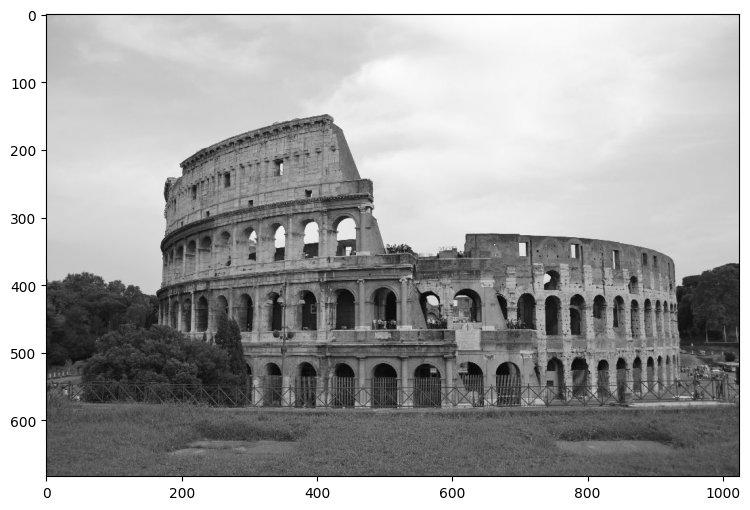

In [67]:
imgmat = np.array(list(imggray.getdata(band=0)), float)
imgmat.shape = (imggray.size[1], imggray.size[0])
print(f"Original type: {type(imgmat)}")

# Change to matrix
imgmat = np.matrix(imgmat)
print(f"New type: {type(imgmat)}")
plt.figure(figsize=(9,6))
plt.imshow(imgmat, cmap='gray')

Il Colosseo bellissimo!

###SVD

We can directly use the $svd$ command from Numpy to operate SVD on the matrix.

Lets first check how the image will look if we only use a single vector to reconstruct the image.

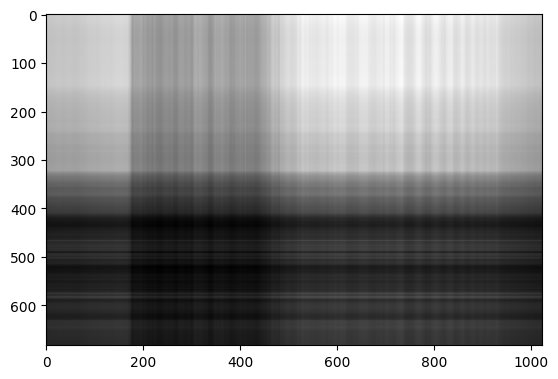

In [68]:
U, sigma, V = np.linalg.svd(imgmat)

# Reconstructing the image
reconstimg = np.matrix(U[:, :1]) * np.diag(sigma[:1]) * np.matrix(V[:1, :])
plt.imshow(reconstimg, cmap='gray');

Using only a single vector gives only the general information - the overall brightness pattern.


Now lets check how does the sigma vector look like.

What do you observe? How many vectors can we use to get a decent reconstruction of the image?
What will happen if we omit the first 1-2 vectors (corresponding to the largest eigen values)?

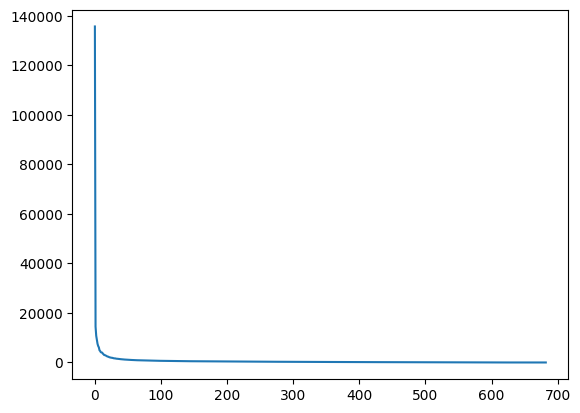

In [69]:
U.shape
sigma.shape
plt.plot(sigma)

The "elbow" in the singular values plot shows how many components (vectors/layers) are enough to get a good approximation of the original image.

In the plot the elbow is at around 10, but visually a decent reconstruction needs about 20-30 components.

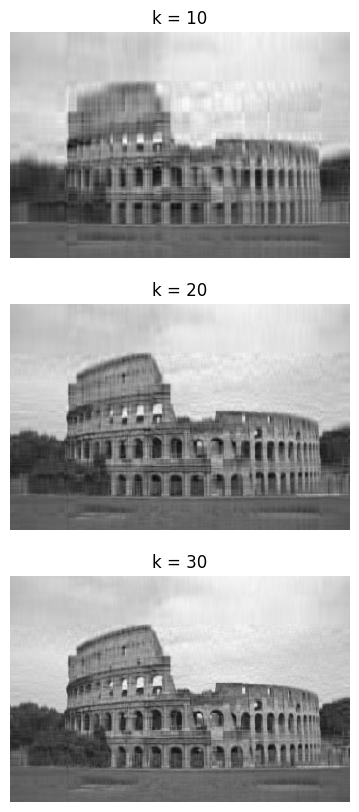

In [70]:
fig, axes = plt.subplots(3, 1, figsize=(5, 10))

for ax, k in zip(axes, [10, 20, 30]):
    reconstimg = np.matrix(U[:, :k]) * np.diag(sigma[:k]) * np.matrix(V[:k, :])
    ax.imshow(reconstimg, cmap='gray')
    ax.set_title(f'k = {k}')
    ax.axis('off')

plt.show()

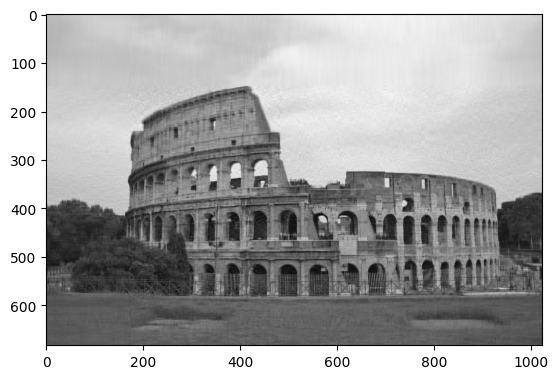

In [71]:
# Range of vectors chosen - j->i
i = 70
j = 0
reconstimg = np.matrix(U[:, j:i]) * np.diag(sigma[j:i]) * np.matrix(V[j:i, :])
plt.imshow(reconstimg, cmap='gray');

If we skip the first 2 components (layers), we lose the most important information about the image, so its overall structure and brightness.

What remains are mostly edges and fine details, which is why the result looks dark and hard to recognize and distinguish the objects.

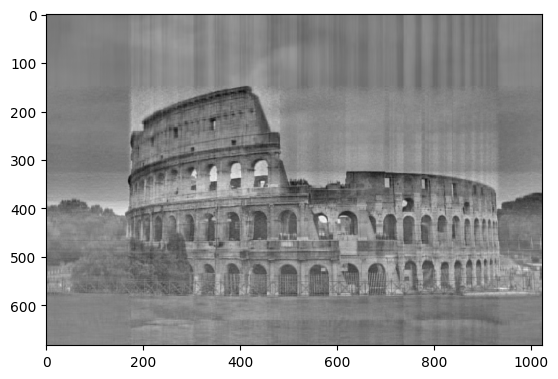

In [72]:
i = 70
j = 2
reconstimg = np.matrix(U[:, j:i]) * np.diag(sigma[j:i]) * np.matrix(V[j:i, :])
plt.imshow(reconstimg, cmap='gray');

# Part 2 - satellite images

Let's repeat the steps with three satellite images of different terrains:

1. forest area
2. urban area
3. ocean area

and note how many eigen values are enough to capture the original image without perceptual degradation.




1. Loading the images

I downloaded the data using https://browser.dataspace.copernicus.eu

- Image 1 - urban area - Rome city centre on 31.10
- Image 2 - forest area - forest in Nowy Sącz county, Beskid Sądecki on 23.05
- Image 3 - sea - Portugal coast of the Atlantic Ocean on 21.09

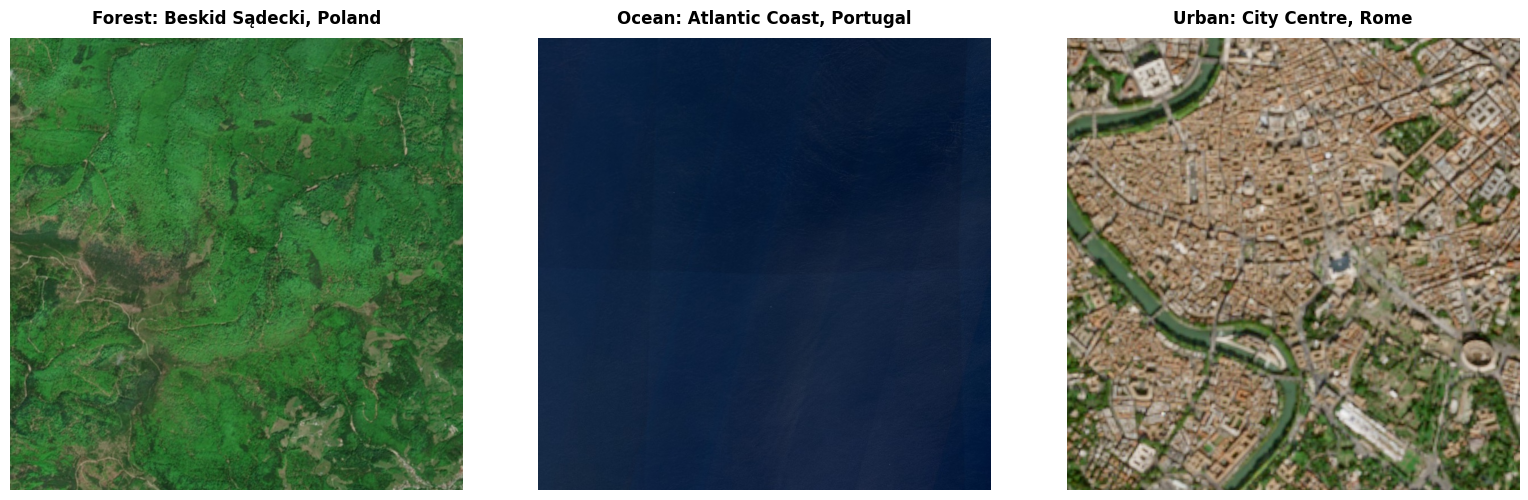

In [73]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

PATHS = {
    "Forest": "/content/drive/My Drive/downstream/machine-learning/SVD/forest.jpg",
    "Ocean": "/content/drive/My Drive/downstream/machine-learning/SVD/ocean.jpg",
    "Urban": "/content/drive/My Drive/downstream/machine-learning/SVD/urban.jpg"
}

titles = [
    "Forest: Beskid Sądecki, Poland",
    "Ocean: Atlantic Coast, Portugal",
    "Urban: City Centre, Rome"
]

for ax, img_path, title in zip(axes, PATHS.values(), titles):

    img = Image.open(img_path)

    ax.imshow(img)
    ax.set_title(title, fontsize=12, fontweight='bold', pad=10)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [74]:
for name, path in PATHS.items():
    with Image.open(path) as img:
        print(f"{name} image size: {img.size} (Width x Height), Format: {img.format}")

Forest image size: (800, 800) (Width x Height), Format: JPEG
Ocean image size: (800, 800) (Width x Height), Format: JPEG
Urban image size: (800, 800) (Width x Height), Format: JPEG


2. Converting to grey scale

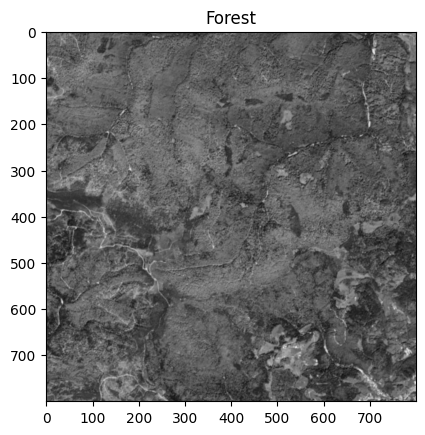

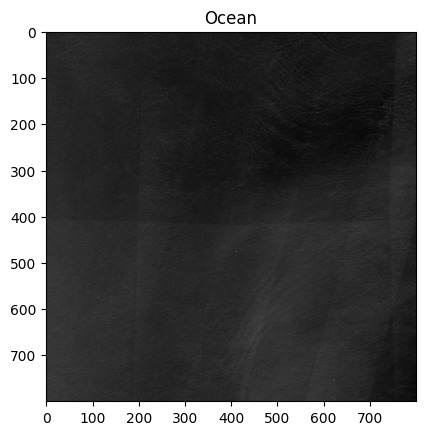

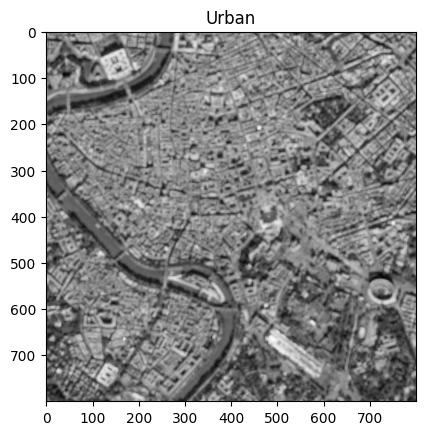

In [75]:
images = {}

for name, path in PATHS.items():
    img = Image.open(path)
    imggray = img.convert('L')
    imgmat = np.matrix(np.array(imggray, dtype=float))

    images[name] = imgmat

    plt.imshow(imgmat, cmap='gray')
    plt.title(name)
    plt.show()

3. Comparison of different number of eigen values

For both urban and forest 70 eigen values is good enough to reconstruct the picture.

4. Sigma plots

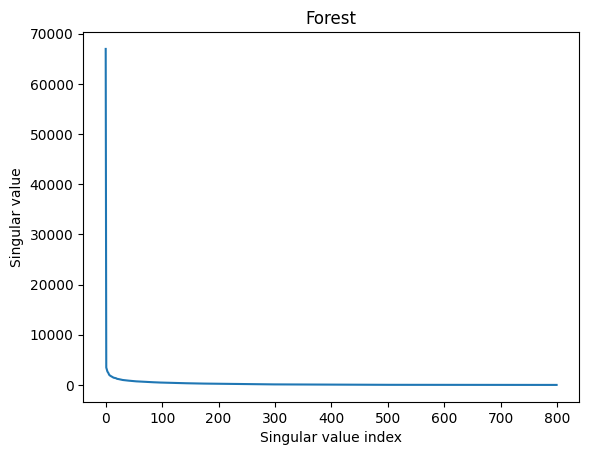

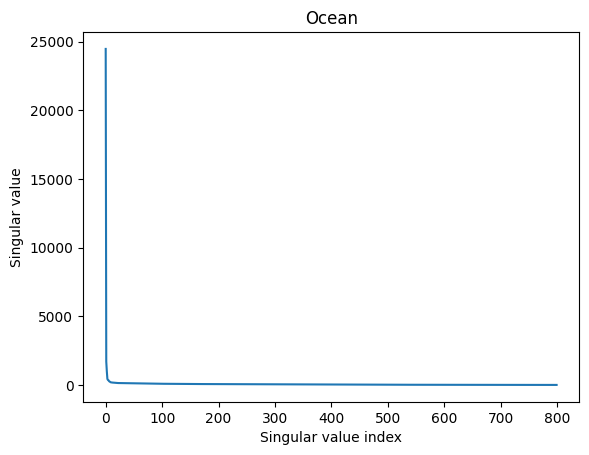

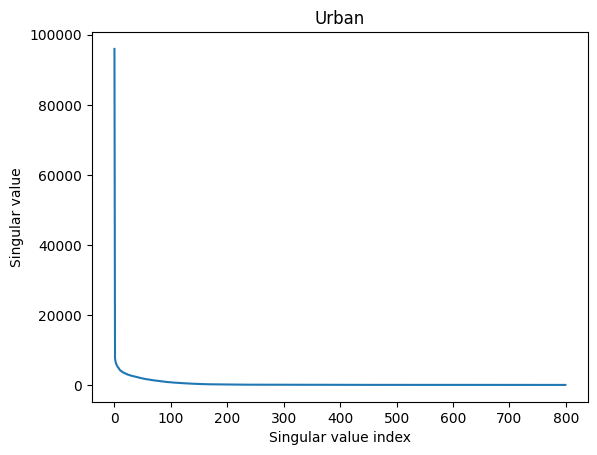

In [76]:
for name, imgmat in images.items():
    U, sigma, V = np.linalg.svd(imgmat)

    plt.plot(sigma)
    plt.title(name)
    plt.xlabel("Singular value index")
    plt.ylabel("Singular value")
    plt.show()

Observations are confirmed based on the sigma plot. The elbow on both urban and forest plots are similar, while the elbow in the ocean plot resembles a "right angle" (L-shape) — which means a lower number of eigenvalues is needed to reconstruct the picture.

5. Comparison of different ranges of eigen values used

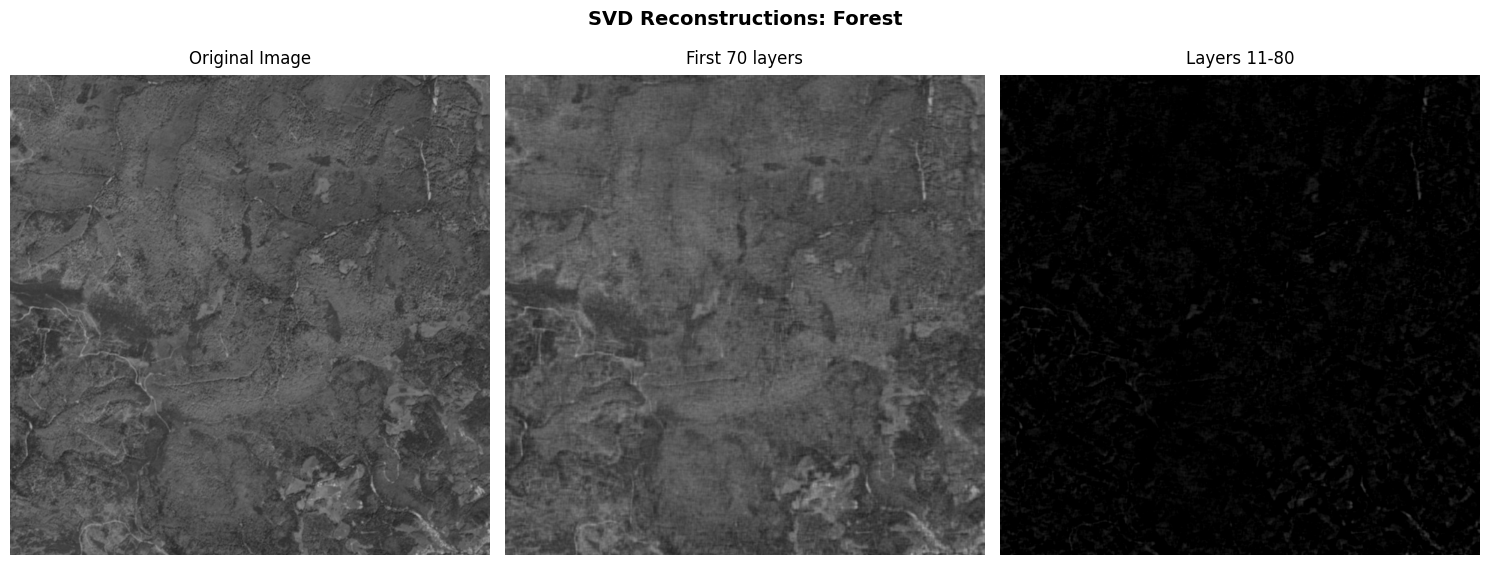

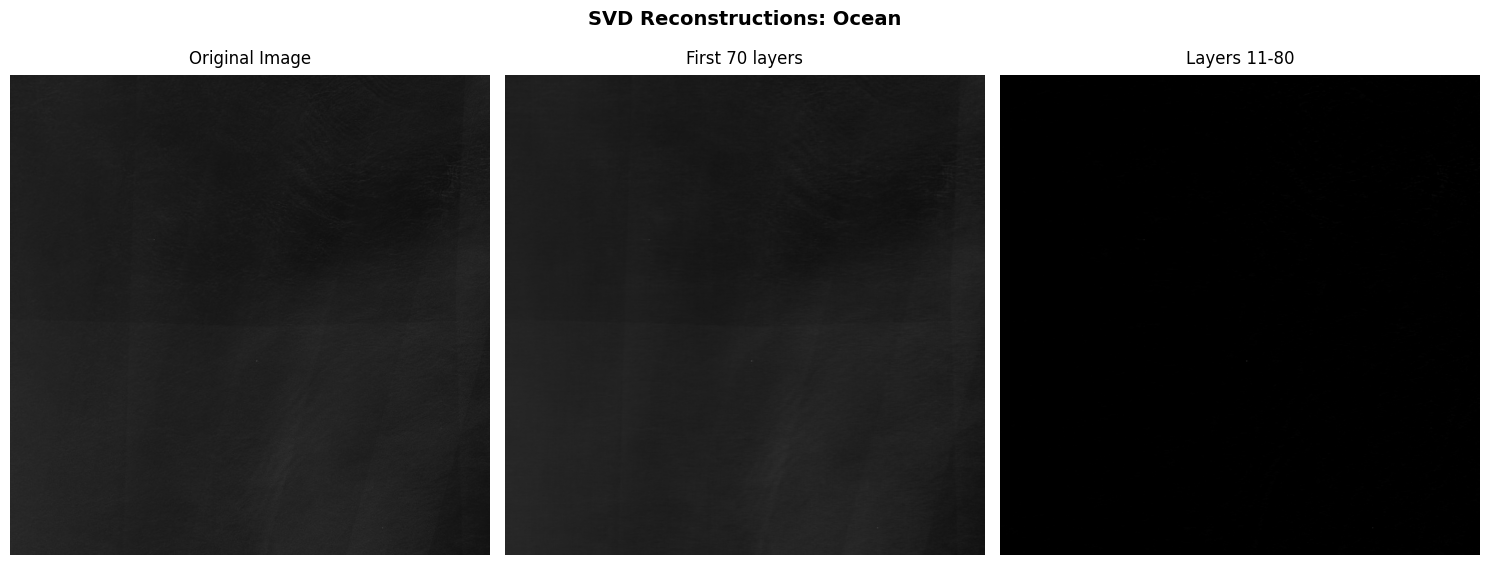

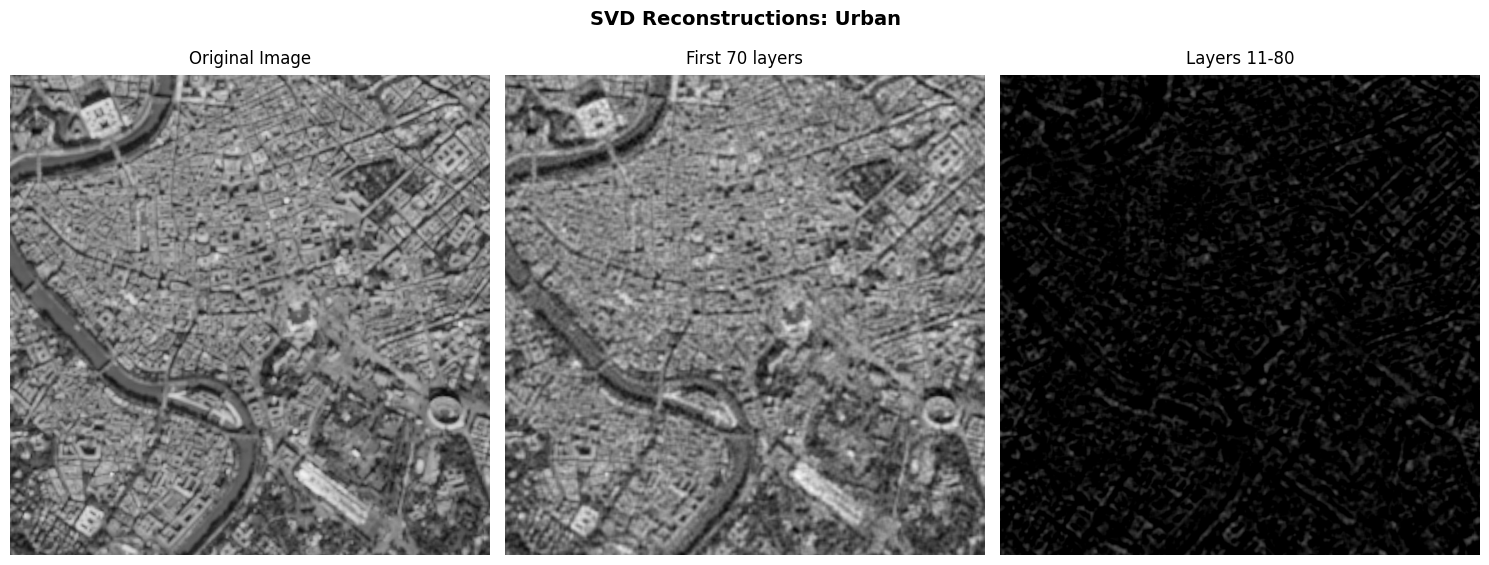

In [77]:
for name, imgmat in images.items():
    U, sigma, V = np.linalg.svd(imgmat)

    i = 70
    j = 0
    reconstimg1 = np.matrix(U[:, j:i]) * np.diag(sigma[j:i]) * np.matrix(V[j:i, :])

    i = 80
    j = 10
    reconstimg2 = np.matrix(U[:, j:i]) * np.diag(sigma[j:i]) * np.matrix(V[j:i, :])

    plt.figure(figsize=(15, 6))

    plt.subplot(1, 3, 1)
    plt.imshow(imgmat, cmap='gray', vmin=0, vmax=255)
    plt.title("Original Image", fontsize=12, pad=8)

    plt.subplot(1, 3, 2)
    plt.imshow(reconstimg1, cmap='gray', vmin=0, vmax=255)
    plt.title("First 70 layers", fontsize=12, pad=8)

    plt.subplot(1, 3, 3)
    plt.imshow(reconstimg2, cmap='gray', vmin=0, vmax=255)
    plt.title("Layers 11-80", fontsize=12, pad=8)

    for ax in plt.gcf().axes:
        ax.axis('off')

    plt.suptitle(f"SVD Reconstructions: {name}", fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

The final comparison also confirms that the first 70 singular values/vectors/layers are enough to reconstruct the satellite images for different terrains. Both the forest and urban area images consist of many intricate details, meaning that skipping the first 10 layers makes recognizing the picture impossible.

The ocean imagery doesn't contain a wide  range of pixel values due to its highly uniform texture, which is why the visual reconstructions do not differ as drastically as the other terrains.